# Análisis Exploratorio de Datos (EDA) - Airbnb Bogotá

**Objetivo:** Comprender la estructura, calidad y distribución de los datos de las colecciones `listings`, `reviews` y `calendar` obtenidas desde MongoDB, antes de aplicar las transformaciones del proceso ETL.

**Colecciones analizadas:**
- `listings`: Información detallada de cada alojamiento (precio, ubicación, tipo, etc.)
- `reviews`: Reseñas de los huéspedes sobre cada alojamiento.
- `calendar`: Disponibilidad diaria y precios por fecha de cada alojamiento.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

# Conexión a MongoDB local (puerto 27017)
try:
    client = MongoClient('localhost', 27017, serverSelectionTimeoutMS=3000)
    db = client['airbnb_bogota']

    df_listings = pd.DataFrame(list(db['listings'].find()))
    df_reviews = pd.DataFrame(list(db['reviews'].find()))
    df_calendar = pd.DataFrame(list(db['calendar'].find()))

    print(f"Listings cargados: {len(df_listings)} registros, {len(df_listings.columns)} columnas")
    print(f"Reviews cargados: {len(df_reviews)} registros, {len(df_reviews.columns)} columnas")
    print(f"Calendar cargados: {len(df_calendar)} registros, {len(df_calendar.columns)} columnas")
except Exception as e:
    print("Error conectando a MongoDB:", e)


Listings cargados: 19187 registros, 91 columnas
Reviews cargados: 527731 registros, 7 columnas
Calendar cargados: 7003255 registros, 6 columnas


## 2.1 Entendimiento General de los Datos
Para cada colección revisamos las primeras filas (`head()`), la cantidad de registros y columnas, y los tipos de datos (`info()`) para entender la estructura inicial de los datos.

In [2]:
# --- LISTINGS ---
print("=" * 60)
print("COLECCIÓN: LISTINGS")
print("=" * 60)
if 'df_listings' in dir() and not df_listings.empty:
    display(df_listings.head(3))
    print(f"\nRegistros: {len(df_listings)}, Columnas: {len(df_listings.columns)}")
    print(f"\nColumnas disponibles: {list(df_listings.columns)}")
    df_listings.info()


COLECCIÓN: LISTINGS


,_id,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,6aca3e58ebd8e85f26ab1944,27841,https://www.airbnb.com/rooms/27841,20260621155658,2026-06-22,city scrape,Rosales Luxury Large 2BR Boutique Apt,Amazing bright 135m2 (1350 sq ft) apartment l...,,https://a0.muscache.com/pictures/38377482/1df3...,...,4.81,4.93,4.81,112727,,3,3,0,0,0.24
1,6aca3e58ebd8e85f26ab1945,65762,https://www.airbnb.com/rooms/65762,20260621155658,2026-06-22,city scrape,Apartaestudios La Candelaria,"In Bogota's historic center, near museums, res...",,https://a0.muscache.com/pictures/miso/Hosting-...,...,4.73,4.79,4.7,100613,,24,22,2,0,0.19
2,6aca3e58ebd8e85f26ab1946,138660,https://www.airbnb.com/rooms/138660,20260621155658,2026-06-22,city scrape,Excelent Studio ROSALES/ ZONA G,Ideal place if you want to settle down in Bogo...,,https://a0.muscache.com/pictures/24594394/1ace...,...,4.77,4.91,4.41,,,1,1,0,0,0.14



Registros: 19187, Columnas: 91

Columnas disponibles: ['_id', 'id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview', 'picture_url', 'host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name', 'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_about', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price', 

In [3]:
# --- REVIEWS ---
print("=" * 60)
print("COLECCIÓN: REVIEWS")
print("=" * 60)
if 'df_reviews' in dir() and not df_reviews.empty:
    display(df_reviews.head(3))
    print(f"\nRegistros: {len(df_reviews)}, Columnas: {len(df_reviews.columns)}")
    df_reviews.info()


COLECCIÓN: REVIEWS


,_id,listing_id,id,date,reviewer_id,reviewer_name,comments
0,6aca3e59ebd8e85f26ab6437,27841,113163,2010-10-06,121485,Paul,I really enjoyed staying at Marcela's place. I...
1,6aca3e59ebd8e85f26ab6438,27841,143106,2010-11-22,288940,Vic,"I, Arrived an hour late from the airport. Mar..."
2,6aca3e59ebd8e85f26ab6439,27841,172475,2011-01-19,98406,Matt,"Wonderful hosts, beautiful spacious apartment,..."



Registros: 527731, Columnas: 7
<class 'pandas.DataFrame'>
RangeIndex: 527731 entries, 0 to 527730
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   _id            527731 non-null  object
 1   listing_id     527731 non-null  str   
 2   id             527731 non-null  str   
 3   date           527731 non-null  str   
 4   reviewer_id    527731 non-null  str   
 5   reviewer_name  527731 non-null  str   
 6   comments       527731 non-null  str   
dtypes: object(1), str(6)
memory usage: 139.9+ MB


In [4]:
# --- CALENDAR ---
print("=" * 60)
print("COLECCIÓN: CALENDAR")
print("=" * 60)
if 'df_calendar' in dir() and not df_calendar.empty:
    display(df_calendar.head(3))
    print(f"\nRegistros: {len(df_calendar)}, Columnas: {len(df_calendar.columns)}")
    df_calendar.info()


COLECCIÓN: CALENDAR


,_id,listing_id,date,available,minimum_nights,maximum_nights
0,6aca3e5febd8e85f26b371aa,15410909,2026-06-22,f,2,1125
1,6aca3e5febd8e85f26b371ab,15410909,2026-06-23,f,2,1125
2,6aca3e5febd8e85f26b371ac,15410909,2026-06-24,f,2,1125



Registros: 7003255, Columnas: 6
<class 'pandas.DataFrame'>
RangeIndex: 7003255 entries, 0 to 7003254
Data columns (total 6 columns):
 #   Column          Dtype 
---  ------          ----- 
 0   _id             object
 1   listing_id      str   
 2   date            str   
 3   available       str   
 4   minimum_nights  str   
 5   maximum_nights  str   
dtypes: object(1), str(5)
memory usage: 532.2+ MB


## 2.2 Calidad de los Datos
Analizamos valores nulos o faltantes por columna, registros duplicados y posibles valores atípicos en variables como `price`, `minimum_nights` y `availability_365`.

### 2.2.1 Valores Nulos
Identificamos qué columnas tienen el mayor porcentaje de valores faltantes para decidir si requieren tratamiento.

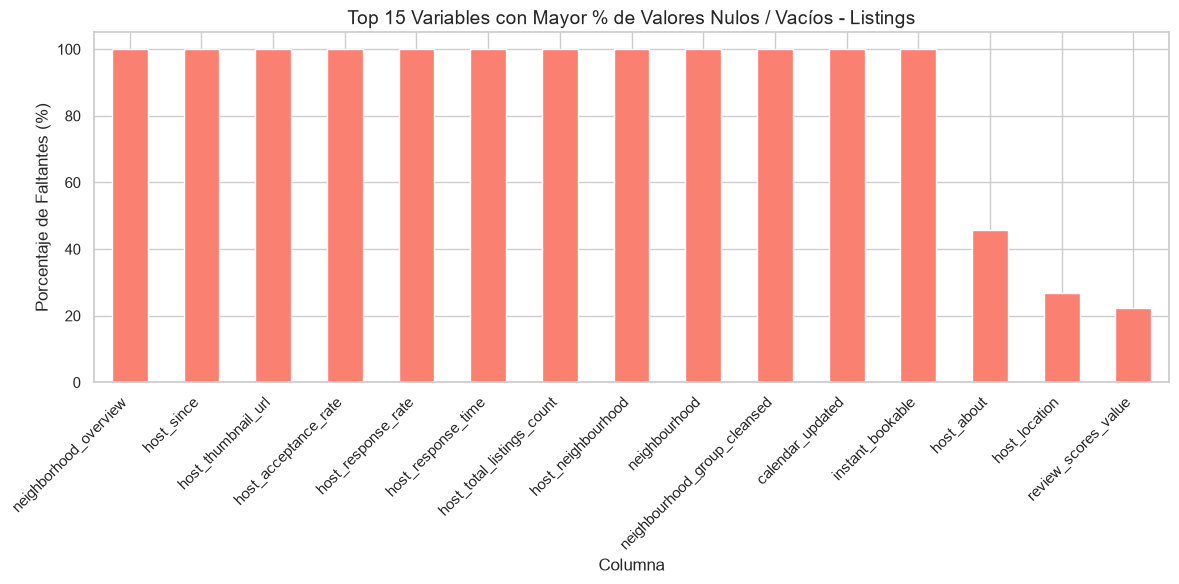


Total de columnas con valores faltantes (vacíos o nulos): 46 de 91


In [5]:
if 'df_listings' in dir() and not df_listings.empty:
    import numpy as np
    # Al importar CSV a MongoDB, los valores vacíos se guardan como cadenas de texto vacías ("")
    # Para detectarlos correctamente, reemplazamos cadenas vacías por NaN
    df_temp_nulos = df_listings.replace(r'^\s*$', np.nan, regex=True)
    nulos = df_temp_nulos.isnull().sum() / len(df_temp_nulos) * 100
    nulos_filtrados = nulos[nulos > 0].sort_values(ascending=False).head(15)
    
    if len(nulos_filtrados) > 0:
        fig, ax = plt.subplots(figsize=(12, 6))
        nulos_filtrados.plot(kind='bar', color='salmon', ax=ax)
        ax.set_title('Top 15 Variables con Mayor % de Valores Nulos / Vacíos - Listings', fontsize=14)
        ax.set_ylabel('Porcentaje de Faltantes (%)')
        ax.set_xlabel('Columna')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
    else:
        print("No se encontraron valores nulos en Listings.")
    
    print(f"\nTotal de columnas con valores faltantes (vacíos o nulos): {(nulos > 0).sum()} de {len(df_listings.columns)}")


### 2.2.2 Registros Duplicados
Verificamos si existen filas completamente duplicadas en cada colección.

In [6]:
print("Registros duplicados por colección:")
print(f"  - Listings: {df_listings.duplicated().sum()} duplicados de {len(df_listings)} registros")
print(f"  - Reviews:  {df_reviews.duplicated().sum()} duplicados de {len(df_reviews)} registros")
print(f"  - Calendar: {df_calendar.duplicated().sum()} duplicados de {len(df_calendar)} registros")

print("\nDecisión: Se aplicará drop_duplicates() en la fase de Transformación para eliminar cualquier duplicado.")


Registros duplicados por colección:
  - Listings: 0 duplicados de 19187 registros
  - Reviews:  0 duplicados de 527731 registros
  - Calendar: 0 duplicados de 7003255 registros

Decisión: Se aplicará drop_duplicates() en la fase de Transformación para eliminar cualquier duplicado.


### 2.2.3 Valores Atípicos (Outliers)
Evaluamos las distribuciones de `price`, `minimum_nights` y `availability_365` mediante diagramas de caja (boxplots) para detectar valores extremos.

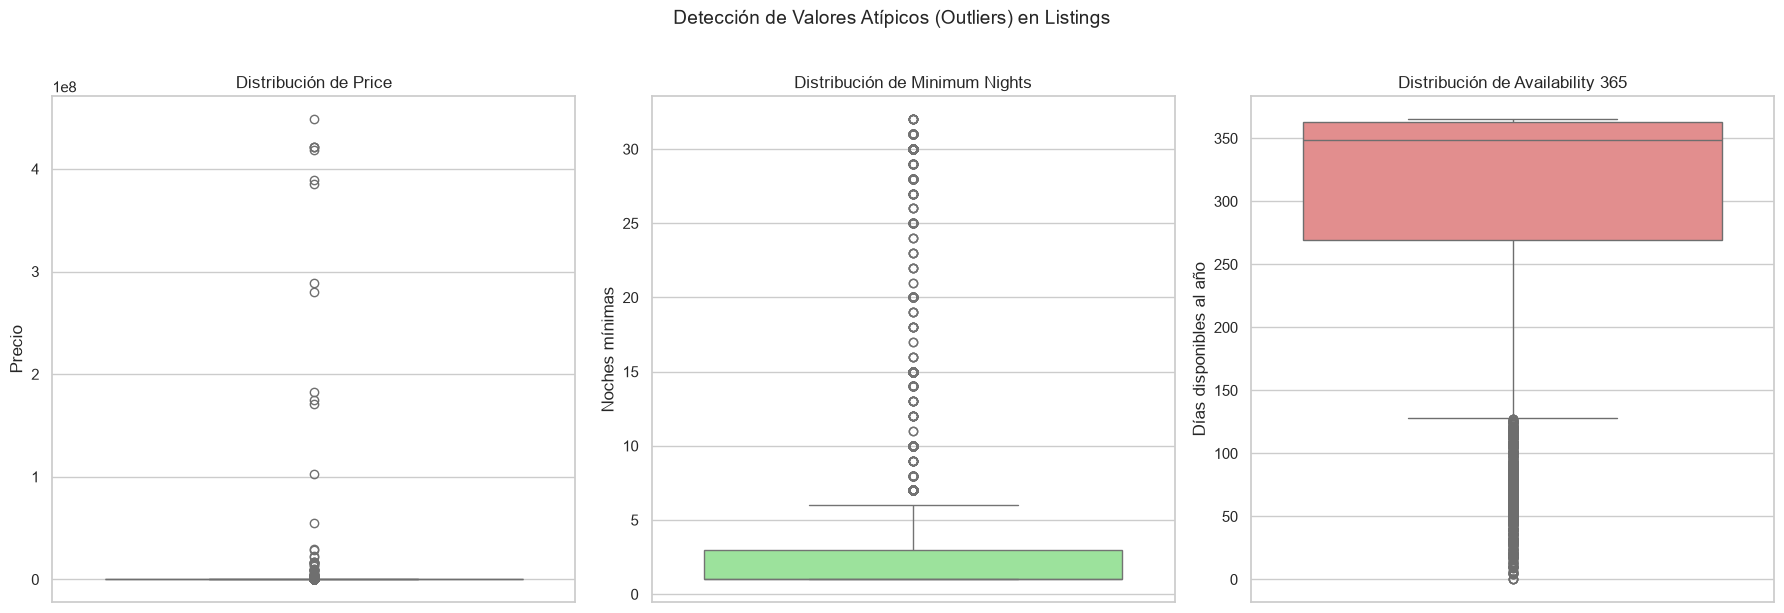


Estadísticas descriptivas de Price:
count    1.899200e+04
mean     4.460266e+05
std      8.829057e+06
min      1.918111e+04
25%      1.100000e+05
50%      1.614600e+05
75%      2.303464e+05
max      4.481766e+08
Name: price_num, dtype: float64


In [7]:
if 'df_listings' in dir() and not df_listings.empty and 'price' in df_listings.columns:
    # Limpieza temporal del precio solo para la visualización del EDA
    df_listings['price_num'] = df_listings['price'].astype(str).str.replace(r'[$,]', '', regex=True)
    df_listings['price_num'] = pd.to_numeric(df_listings['price_num'], errors='coerce')

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # Boxplot de Price
    sns.boxplot(y=df_listings['price_num'], ax=axes[0], color='skyblue')
    axes[0].set_title('Distribución de Price', fontsize=12)
    axes[0].set_ylabel('Precio')
    
    # Boxplot de Minimum Nights
    if 'minimum_nights' in df_listings.columns:
        sns.boxplot(y=pd.to_numeric(df_listings['minimum_nights'], errors='coerce'), ax=axes[1], color='lightgreen')
        axes[1].set_title('Distribución de Minimum Nights', fontsize=12)
        axes[1].set_ylabel('Noches mínimas')
    
    # Boxplot de Availability 365
    if 'availability_365' in df_listings.columns:
        sns.boxplot(y=pd.to_numeric(df_listings['availability_365'], errors='coerce'), ax=axes[2], color='lightcoral')
        axes[2].set_title('Distribución de Availability 365', fontsize=12)
        axes[2].set_ylabel('Días disponibles al año')
    
    plt.suptitle('Detección de Valores Atípicos (Outliers) en Listings', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()
    
    # Estadísticas descriptivas
    print("\nEstadísticas descriptivas de Price:")
    print(df_listings['price_num'].describe())


**Interpretación de los Outliers:**
- **Price:** Se observan valores extremadamente altos que distorsionan la distribución. La mayoría de alojamientos se concentra en precios bajos, pero existen listados con precios muy elevados. Por esto, en la transformación se implementará una categorización por rangos (Económico, Medio, Alto).
- **Minimum Nights:** Algunos alojamientos exigen un número excesivamente alto de noches mínimas, lo cual puede representar errores de configuración o propiedades de largo plazo.
- **Availability 365:** La distribución muestra dos grupos principales: alojamientos con muy poca disponibilidad y otros disponibles casi todo el año.

## 2.3 Posibles Transformaciones

A partir del análisis exploratorio realizado, se identificaron los siguientes problemas y se proponen las siguientes transformaciones para resolverlos en la etapa de **Transformación** del proceso ETL:

| # | Problema Detectado | Transformación Propuesta | Colección Afectada |
|---|---|---|---|
| 1 | El campo `price` viene como texto con símbolos (`$` y comas) | Eliminar los símbolos `$` y `,`, luego convertir a tipo numérico (float) | Listings y Calendar |
| 2 | Las fechas vienen como texto sin formato estándar | Convertir a formato fecha `YYYY-MM-DD` y derivar nuevas columnas: año, mes, día y trimestre | Calendar y Reviews |
| 3 | Existen registros duplicados en las colecciones | Eliminar filas duplicadas con `drop_duplicates()` | Listings, Reviews y Calendar |
| 4 | La columna `amenities` contiene listas en formato de texto (arreglos como string) | Expandir y limpiar para que sea legible como texto separado por comas | Listings |
| 5 | Se detectaron valores atípicos extremos en `price` y `minimum_nights` | Crear una nueva columna de categorización por rangos de precio: **Económico**, **Medio** y **Alto** | Listings |
| 6 | Algunos campos de texto contienen caracteres Unicode corruptos (emojis mal codificados) | Limpiar caracteres no válidos (surrogates) que impiden la exportación a SQLite y Excel | Listings |
| 7 | Algunas columnas presentan un alto porcentaje de valores nulos | Identificar y documentar cuáles columnas tienen más del 50% de nulos para decidir si se conservan o se descartan según el análisis requerido | Listings |

### Agrupaciones propuestas
Se evaluó la posibilidad de **agrupar o resumir datos del calendario por mes**, lo cual es útil para identificar tendencias de estacionalidad en precios y disponibilidad. Esta agrupación se puede derivar fácilmente gracias a las variables temporales creadas (year, month, quarter).

### Estandarización de formatos
- **Fecha:** Se estandarizará al formato `YYYY-MM-DD`.
- **Moneda:** Se eliminarán símbolos y se convertirá a tipo numérico.
- **Texto:** Se limpiarán caracteres especiales corruptos y se expandirán campos anidados como `amenities`.

Estas transformaciones serán implementadas de manera formal en la clase `Transformacion` dentro del archivo `src/transformacion.py` del proyecto ETL.


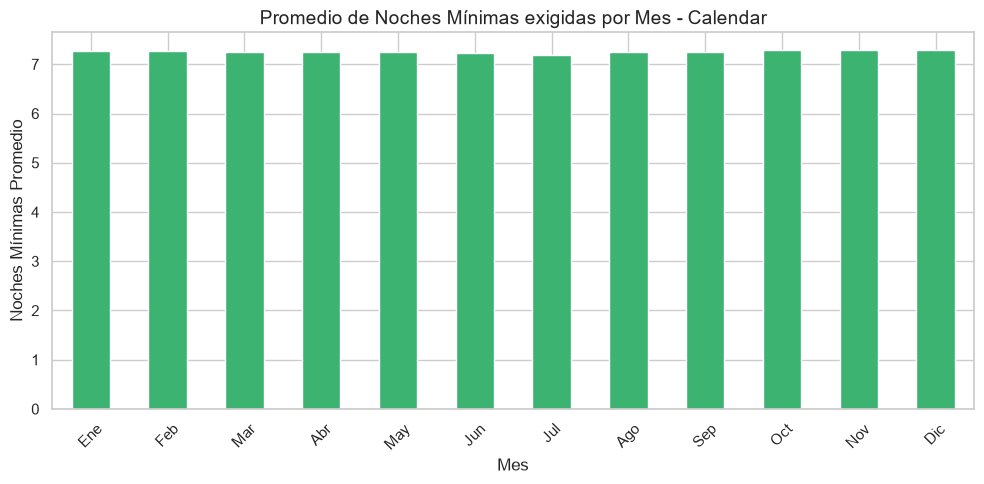


Esta agrupación demuestra la utilidad de derivar la variable 'month' en la transformación.


In [8]:
if 'df_calendar' not in globals():
    print("La variable 'df_calendar' no existe. Asegúrate de ejecutar la celda de conexión a MongoDB arriba.")
elif df_calendar.empty:
    print("El DataFrame df_calendar está vacío.")
elif 'minimum_nights' not in df_calendar.columns:
    print(f"La columna 'minimum_nights' no se encuentra en df_calendar. Columnas disponibles: {list(df_calendar.columns)}")
else:
    # Preparamos temporalmente los datos para esta visualización
    cal_temp = df_calendar.copy()
    cal_temp['minimum_nights'] = pd.to_numeric(cal_temp['minimum_nights'], errors='coerce')
    cal_temp['date'] = pd.to_datetime(cal_temp['date'], errors='coerce')
    cal_temp['month'] = cal_temp['date'].dt.month
    
    # Agrupamos por mes y calculamos el promedio de noches mínimas
    noches_por_mes = cal_temp.groupby('month')['minimum_nights'].mean()
    
    if noches_por_mes.empty or noches_por_mes.isna().all():
        print("No se pudo calcular el promedio. Verifica los datos.")
    else:
        fig, ax = plt.subplots(figsize=(10, 5))
        noches_por_mes.plot(kind='bar', color='mediumseagreen', ax=ax)
        ax.set_title('Promedio de Noches Mínimas exigidas por Mes - Calendar', fontsize=14)
        ax.set_xlabel('Mes')
        ax.set_ylabel('Noches Mínimas Promedio')
        # Ajustar xticklabels según la cantidad de meses que existan en la data
        meses_nombres = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']
        ax.set_xticklabels([meses_nombres[int(m)-1] for m in noches_por_mes.index], rotation=45)
        plt.tight_layout()
        plt.show()
        
        print("\nEsta agrupación demuestra la utilidad de derivar la variable 'month' en la transformación.")


## 2.4 Documentación de Hallazgos y Decisiones

### Hallazgos principales:

1. **Inconsistencias en Tipos de Datos:** El campo `price` en Listings y Calendar viene como cadena de texto con símbolos `$` y comas. Esto impide hacer cálculos matemáticos. Lo mismo ocurre con los campos de fecha que vienen como strings sin formato estándar.

2. **Variables Anidadas:** La columna `amenities` en `listings` contiene listas de servicios en formato de arreglo como string (ej: `["Wifi", "Pool"]`). Es necesario expandirlas para facilitar su lectura y análisis.

3. **Valores Faltantes:** Varias columnas presentan un alto porcentaje de nulos (especialmente campos como `license`, `neighborhood_overview` o columnas de reseñas). Se documentan pero no se eliminan las columnas completas, ya que podrían ser útiles para análisis específicos.

4. **Duplicados:** Se verificó la presencia de registros duplicados. Aunque en esta ejecución fueron cero, se mantiene la limpieza con `drop_duplicates()` como medida preventiva para futuras cargas de datos.

5. **Outliers:** Las variables `price` y `minimum_nights` presentan valores atípicos extremos (colas muy largas hacia la derecha). Se decidió implementar una **categorización por rangos** en lugar de eliminar los outliers, para conservar la información y facilitar el análisis de segmentos.

6. **Caracteres corruptos:** Se detectaron emojis y caracteres Unicode mal codificados (surrogates) en las descripciones de algunos alojamientos, los cuales generaban errores al intentar guardar los datos en SQLite y Excel. Se decidió limpiarlos automáticamente.

7. **Estacionalidad:** La agrupación del calendario por mes muestra variaciones en el precio promedio, lo cual sugiere la existencia de estacionalidad en los precios de Airbnb en Bogotá. La derivación de variables temporales (año, mes, trimestre) en la transformación permitirá profundizar en este análisis.

### Decisiones que impactan la fase de Transformación:
- Se implementará normalización de precios (eliminar `$` y convertir a numérico).
- Se convertirán las fechas a formato `YYYY-MM-DD` y se derivarán año, mes, día y trimestre.
- Se categorizarán los precios en rangos: Económico, Medio y Alto.
- Se expandirán los campos anidados como `amenities`.
- Se limpiarán caracteres Unicode corruptos antes de la carga.


### Correlaciones Relevantes
Exploramos si existe relación entre las variables numéricas principales de Listings.

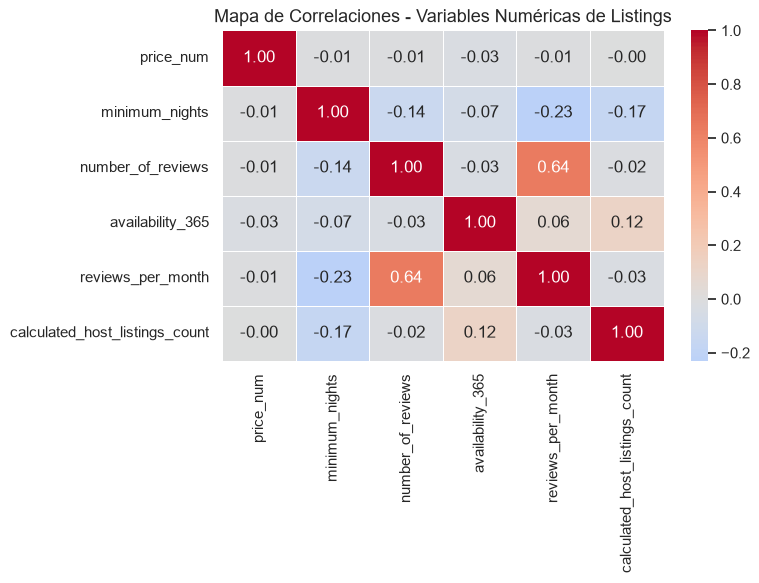


Interpretación:
- Valores cercanos a 1 o -1 indican correlación fuerte.
- Valores cercanos a 0 indican poca o nula correlación.


In [9]:
if 'df_listings' in dir() and not df_listings.empty:
    # Seleccionamos columnas numéricas relevantes para la correlación
    cols_num = []
    for col in ['price_num', 'minimum_nights', 'number_of_reviews', 'availability_365',
                'reviews_per_month', 'calculated_host_listings_count']:
        if col in df_listings.columns:
            df_listings[col] = pd.to_numeric(df_listings[col], errors='coerce')
            cols_num.append(col)
    
    if len(cols_num) >= 2:
        corr_matrix = df_listings[cols_num].corr()
        
        fig, ax = plt.subplots(figsize=(8, 6))
        sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0,
                    fmt='.2f', linewidths=0.5, ax=ax)
        ax.set_title('Mapa de Correlaciones - Variables Numéricas de Listings', fontsize=13)
        plt.tight_layout()
        plt.show()
        
        print("\nInterpretación:")
        print("- Valores cercanos a 1 o -1 indican correlación fuerte.")
        print("- Valores cercanos a 0 indican poca o nula correlación.")
    else:
        print("No hay suficientes columnas numéricas para calcular correlaciones.")
